# Лабораторная работа №1 — Анализ медицинских данных

1. Считать csv файл с данными.
    *   [Ссылка на файл](https://drive.google.com/file/d/12HHlCr_yO8bx6icKqEs7N2QBt8fqOHYS/)
    *   Столбец для предсказания ***stroke***
2. Провести первичный анализ данных (количество признаков, пропуски, распределение признаков и т.д.). Визуализировать результаты.
3. Провести очистку и подготовку данных для обучения (балансировка, разбиение, кодировка вектора признаков).
4. Обучить классические ML модели.
    *   наивный байесовский
    *   логистическая регрессия
    *   дерево решений
    *   случайный лес/бустинг
5. Построить небольшую нейронную сеть и обучить её.

  
    
    
*Для работы можно использовать любые библиотеки, кроме готовых AutoML фреймворков*

## 1. Чтение CSV-файла

In [345]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, classification_report,
    precision_recall_curve, ConfusionMatrixDisplay, PrecisionRecallDisplay,
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    RandomizedSearchCV, cross_val_predict,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ResamplingPipeline

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 3
SEARCH_SCORING = "average_precision"

DATA_PATH = Path("datasets") / "AMD1.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,id,gender,age,birthplace,birthmonth,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,Buenos Aires,May,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,Shanghai,Dec,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,Moscow,Nov,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,Manila,Mar,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,Tehran,Apr,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Первичный анализ данных и визуализация
Обзор исходного CSV: типы, пропуски, дубликаты, распределения и баланс классов.

In [346]:
print(f"Строк: {len(df)}, столбцов: {df.shape[1]}")
print("Дубликатов:", df.duplicated().sum())
data_overview = pd.DataFrame({"Тип": df.dtypes.astype(str), "Пропуски": df.isna().sum(),
                              "Уникальные значения": df.nunique()})
data_overview

Строк: 5110, столбцов: 14
Дубликатов: 0


,Тип,Пропуски,Уникальные значения
id,int64,0,5110
gender,str,0,3
age,float64,0,104
birthplace,str,0,50
birthmonth,str,0,12
hypertension,int64,0,2
heart_disease,int64,0,2
ever_married,str,0,2
work_type,str,0,5
Residence_type,str,0,2


In [347]:
df.describe().round(2)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.1,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.3,0.23,45.28,7.85,0.22
min,67.00,0.08,0.0,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.0,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.0,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.0,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.0,1.00,271.74,97.60,1.00


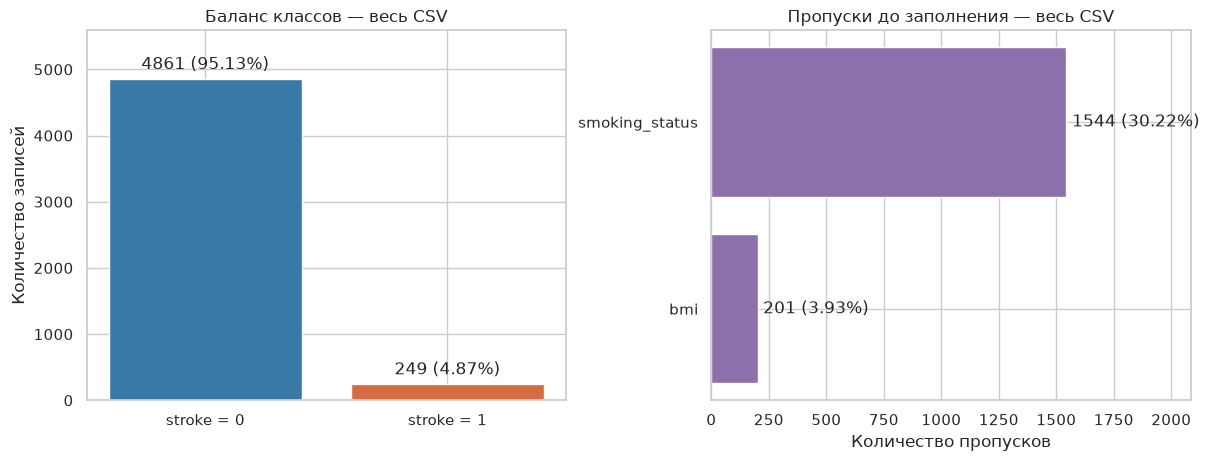

In [348]:
sns.set_theme(style="whitegrid", font="DejaVu Sans")
stroke_palette = {"stroke = 0": "#3979A8", "stroke = 1": "#D66A42"}
eda_data = df.drop(columns=["id", "stroke"]).copy()
eda_data["stroke_group"] = df["stroke"].map({0: "stroke = 0", 1: "stroke = 1"})
eda_data["smoking_status"] = eda_data["smoking_status"].fillna("Unknown")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
counts = df["stroke"].value_counts().reindex([0, 1], fill_value=0)
bars = axes[0].bar(["stroke = 0", "stroke = 1"], counts, color=list(stroke_palette.values()))
axes[0].bar_label(bars, labels=[f"{n} ({n / len(df):.2%})" for n in counts], padding=4)
axes[0].set(title="Баланс классов — весь CSV", ylabel="Количество записей", ylim=(0, counts.max() * 1.15))
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()
bars = axes[1].barh(missing.index, missing.values, color="#8C70AC")
axes[1].bar_label(bars, labels=[f"{n} ({n / len(df):.2%})" for n in missing], padding=4)
axes[1].set(title="Пропуски до заполнения — весь CSV", xlabel="Количество пропусков", xlim=(0, missing.max() * 1.35))
plt.show()

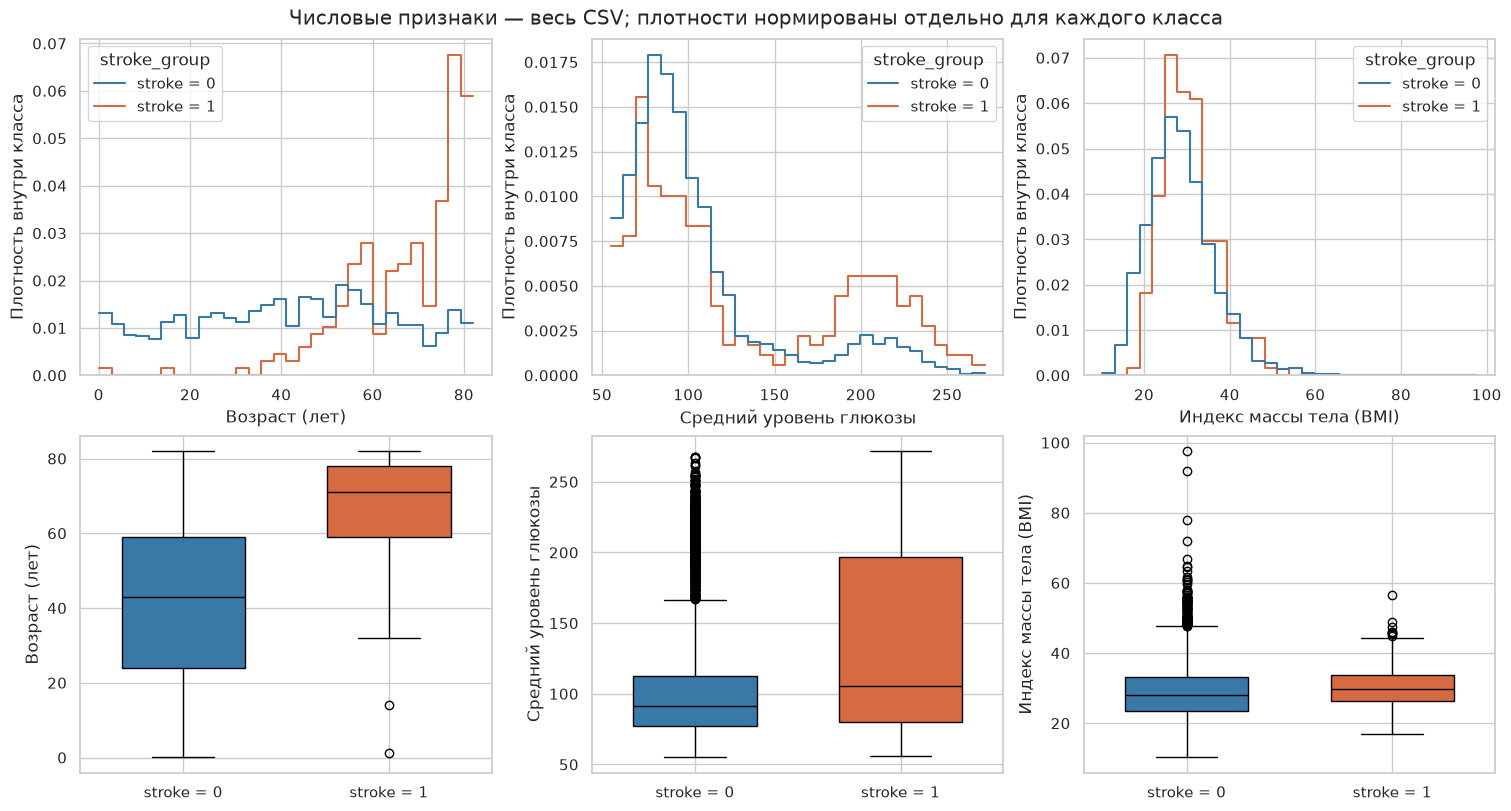

In [349]:
numeric_columns = ["age", "avg_glucose_level", "bmi"]
labels = {"age": "Возраст (лет)", "avg_glucose_level": "Средний уровень глюкозы", "bmi": "Индекс массы тела (BMI)"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for column, ax_hist, ax_box in zip(numeric_columns, axes[0], axes[1]):
    sns.histplot(data=eda_data, x=column, hue="stroke_group", hue_order=list(stroke_palette),
                 palette=stroke_palette, bins=30, stat="density", common_norm=False,
                 element="step", fill=False, ax=ax_hist)
    ax_hist.set(xlabel=labels[column], ylabel="Плотность внутри класса")
    groups = list(stroke_palette)
    values = [eda_data.loc[eda_data["stroke_group"] == group, column].dropna()
              for group in groups]
    boxes = ax_box.boxplot(values, orientation="vertical", tick_labels=groups,
                           patch_artist=True, widths=0.6,
                           medianprops={"color": "black"})
    for box, group in zip(boxes["boxes"], groups):
        box.set_facecolor(stroke_palette[group])
    ax_box.set(xlabel="", ylabel=labels[column])
fig.suptitle("Числовые признаки — весь CSV; плотности нормированы отдельно для каждого класса")
plt.show()

На следующих графиках подпись `k/n` означает число записей с `stroke=1` и общий размер категории. Категории городов показаны отдельно из-за их количества.


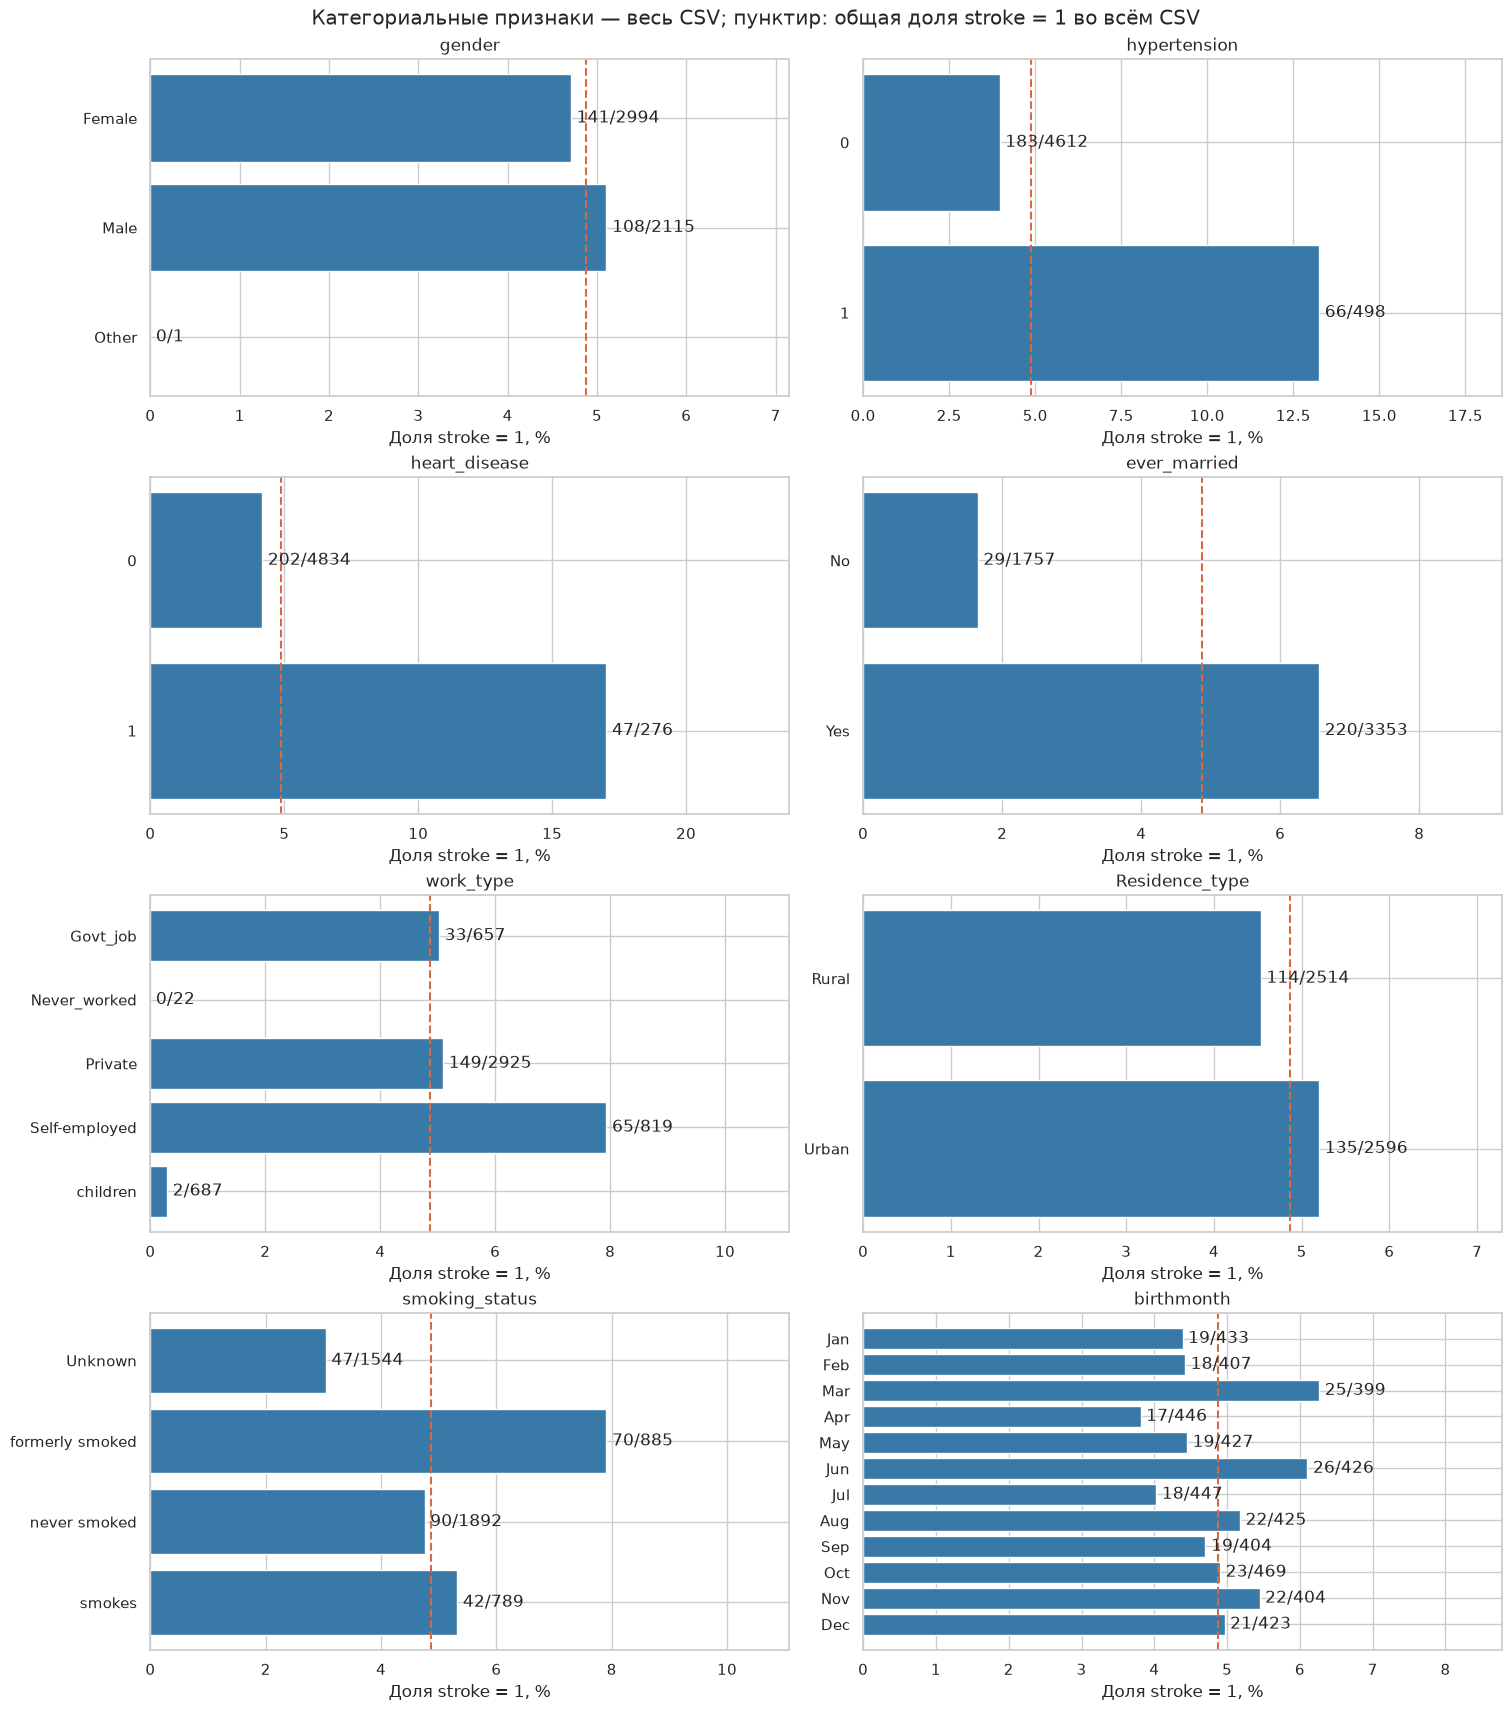

In [350]:
categorical_columns = ["gender", "hypertension", "heart_disease", "ever_married",
                       "work_type", "Residence_type", "smoking_status", "birthmonth"]
fig, axes = plt.subplots(4, 2, figsize=(15, 17), layout="constrained")
for column, ax in zip(categorical_columns, axes.flat):
    stats = eda_data.groupby(column, observed=True)["stroke_group"].agg(
        total="size", positive=lambda values: (values == "stroke = 1").sum())
    if column == "birthmonth":
        stats = stats.reindex(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    rate = 100 * stats["positive"] / stats["total"]
    bars = ax.barh(stats.index.astype(str), rate, color="#3979A8")
    ax.bar_label(bars, labels=[f"{k}/{n}" for k, n in zip(stats["positive"], stats["total"])], padding=4)
    ax.axvline(df["stroke"].mean() * 100, color="#D66A42", linestyle="--")
    ax.set(title=column, xlabel="Доля stroke = 1, %", xlim=(0, max(5, rate.max()) * 1.4))
    ax.invert_yaxis()
fig.suptitle("Категориальные признаки — весь CSV; пунктир: общая доля stroke = 1 во всём CSV")
plt.show()

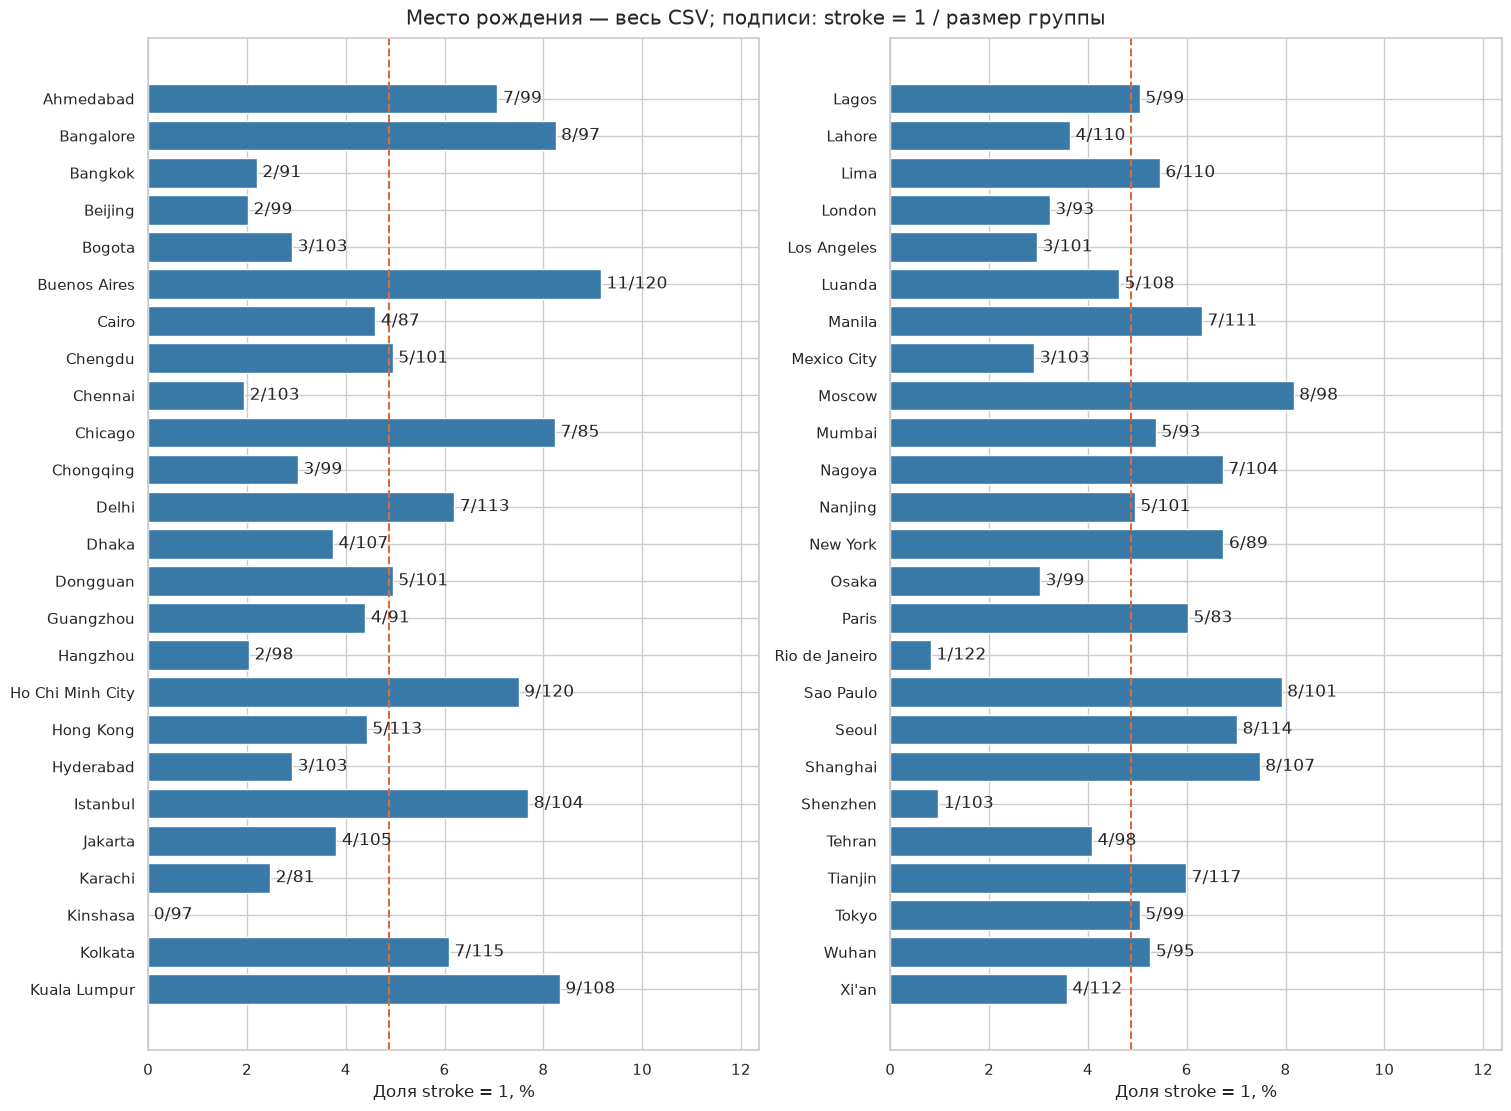

In [351]:
city_stats = eda_data.groupby("birthplace")["stroke_group"].agg(
    total="size", positive=lambda values: (values == "stroke = 1").sum()).sort_index()
city_stats["rate"] = 100 * city_stats["positive"] / city_stats["total"]
fig, axes = plt.subplots(1, 2, figsize=(15, 11), layout="constrained", sharex=True)
for ax, part in zip(axes, [city_stats.iloc[:25], city_stats.iloc[25:]]):
    bars = ax.barh(part.index, part["rate"], color="#3979A8")
    ax.bar_label(bars, labels=[f"{k}/{n}" for k, n in zip(part["positive"], part["total"])], padding=4)
    ax.axvline(df["stroke"].mean() * 100, color="#D66A42", linestyle="--")
    ax.set(xlabel="Доля stroke = 1, %", xlim=(0, city_stats["rate"].max() * 1.35))
    ax.invert_yaxis()
fig.suptitle("Место рождения — весь CSV; подписи: stroke = 1 / размер группы")
plt.show()

## 3. Очистка и подготовка данных
### 3.1. Разбиение и отделение целевой переменной
Удаляем идентификатор, отделяем `stroke` и сохраняем доли классов при разбиении 80/20. Все обучаемые преобразования и балансировка выполняются только на обучающей части. Все модели и подбор порогов используют одинаковые строки в каждом фолде.


In [352]:
X = df.drop(columns=["id", "stroke"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

# Одни и те же индексы фолдов для всех поисков и проверочных прогнозов
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train))

split_summary = pd.DataFrame({
    "Количество строк": [len(y_train), len(y_test)],
    "Количество признаков": [X_train.shape[1], X_test.shape[1]],
    "stroke = 1": [int(y_train.sum()), int(y_test.sum())],
    "Доля stroke = 1, %": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Test"])
split_summary.round(2)

,Количество строк,Количество признаков,stroke = 1,"Доля stroke = 1, %"
Train,4088,12,199,4.87
Test,1022,12,50,4.89


### 3.2. Кодирование, масштабирование и балансировка
Один шаблон `preprocessor` используется всеми моделями через `clone`. Числовые признаки заполняем медианой с индикатором пропуска и стандартизируем. Масштабирование деревьям не требуется, но позволяет использовать общий шаблон. Категории заполняем `Unknown` и кодируем one-hot; бинарные признаки оставляем без изменений.

`birthplace` и `birthmonth` выделены в группу `birth` и исключены из остальных категорий. У каждого классификатора поиск проверяет использование этой группы или её удаление (`preprocessor__birth="drop"`). Все преобразования обучаются внутри фолдов, а каждая модель получает независимую копию шаблона. Test не балансируем.


In [353]:
numeric_features = ["age", "avg_glucose_level", "bmi"]
categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
binary_features = ["hypertension", "heart_disease"]
birth_features = ["birthplace", "birthmonth"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
# Необученный шаблоны, каждая модель получает независимую копию через clone
preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_transformer), numeric_features),
    ("categorical", clone(categorical_transformer),
     [c for c in categorical_features if c not in birth_features]),
    ("birth", clone(categorical_transformer), birth_features),
    ("binary", "passthrough", binary_features),
])

## 4. Обучение классических ML-моделей
Метрики класса 1: precision, recall, F1; качество ранжирования — Average Precision и ROC-AUC. DummyClassifier служит общим ориентиром. Параметры подбираются на train.

In [354]:
def evaluate_classifier(y_true, prediction, probability):
    return {
        "Accuracy": accuracy_score(y_true, prediction),
        "Precision (stroke=1)": precision_score(y_true, prediction, zero_division=0),
        "Recall (stroke=1)": recall_score(y_true, prediction, zero_division=0),
        "F1 (stroke=1)": f1_score(y_true, prediction, zero_division=0),
        "Average Precision": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability),
    }

def print_model_conclusion(name, metrics):
    row = metrics.iloc[0]
    print(f"{name}: F1 = {row['F1 (stroke=1)']:.3f}; "
          f"обнаружено {row['Recall (stroke=1)']:.0%} положительных случаев; "
          f"точность положительных прогнозов — {row['Precision (stroke=1)']:.1%}.")

def select_f1_threshold(target, probability):
    precision, recall, thresholds = precision_recall_curve(target, probability)
    scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    index = np.flatnonzero(np.isclose(scores, scores.max(), rtol=0, atol=1e-12))[-1]
    return (float(thresholds[index]), float(scores[index]))


def plot_classifier_results(y_true, prediction, probability, name, axes=None):
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    ConfusionMatrixDisplay.from_predictions(
        y_true, prediction, display_labels=["stroke = 0", "stroke = 1"],
        cmap="Blues", colorbar=False, ax=axes[0])
    axes[0].set(title=name, xlabel="Предсказанный класс", ylabel="Истинный класс")
    PrecisionRecallDisplay.from_predictions(y_true, probability, name=name, ax=axes[1])
    axes[1].axhline(np.mean(y_true), linestyle="--", color="gray", label="Доля stroke = 1")
    axes[1].set(title="Precision–Recall: test", xlabel="Полнота (Recall)", ylabel="Точность (Precision)")
    axes[1].legend()

In [355]:
dummy_model = DummyClassifier(strategy="prior").fit(X_train, y_train)
dummy_metrics = pd.DataFrame({
    "DummyClassifier": evaluate_classifier(y_test, dummy_model.predict(X_test), dummy_model.predict_proba(X_test)[:, 1])
}).T
dummy_metrics.round(4)

,Accuracy,Precision (stroke=1),Recall (stroke=1),F1 (stroke=1),Average Precision,ROC-AUC
DummyClassifier,0.9511,0.0,0.0,0.0,0.0489,0.5


### 4.1. Наивный байесовский классификатор
Используем `GaussianNB` как базовую модель. Нормальность распределений, особенно для one-hot-признаков, является упрощением этой модели.

Все преобразования обучаются внутри Pipeline на обучающем фолде: медиана числовых признаков и индикатор пропусков BMI, масштабирование, заполнение категорий значением `Unknown`, one-hot-кодирование. Передаём исходный `X_train`, а не заранее заполненные данные, чтобы избежать утечки при кросс-валидации.


In [356]:
nb_pipeline = ResamplingPipeline([
    ("preprocessor", clone(preprocessor)),
    ("sampler", "passthrough"),
    ("classifier", GaussianNB()),
])
nb_search = GridSearchCV(
    nb_pipeline,
    param_grid={
        "preprocessor__birth": [clone(categorical_transformer), "drop"],
        "sampler": ["passthrough", RandomOverSampler(random_state=RANDOM_STATE)],
        "classifier__var_smoothing": [1e-9, 1e-5, 1e-2, 1e-1],
    },
    scoring=SEARCH_SCORING, refit=True,
    cv=cv_splits, n_jobs=1, error_score="raise",
)
nb_search.fit(X_train, y_train)
nb_model = nb_search.best_estimator_
nb_search_results = pd.DataFrame(nb_search.cv_results_)[[
    "params", "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score")
print("Лучшие параметры:", nb_search.best_params_)
print(f"Average Precision при подборе: {nb_search.best_score_:.3f}")
nb_search_results.round(4)

Лучшие параметры: {'classifier__var_smoothing': 0.1, 'preprocessor__birth': 'drop', 'sampler': RandomOverSampler(random_state=42)}
Average Precision при подборе: 0.185


,params,mean_test_score,std_test_score,rank_test_score
15,"{'classifier__var_smoothing': 0.1, 'preprocess...",0.1850,0.0099,1
13,"{'classifier__var_smoothing': 0.1, 'preprocess...",0.1842,0.0075,2
11,"{'classifier__var_smoothing': 0.01, 'preproces...",0.1829,0.0135,3
14,"{'classifier__var_smoothing': 0.1, 'preprocess...",0.1823,0.0121,4
12,"{'classifier__var_smoothing': 0.1, 'preprocess...",0.1815,0.0089,5
10,"{'classifier__var_smoothing': 0.01, 'preproces...",0.1779,0.0110,6
7,"{'classifier__var_smoothing': 1e-05, 'preproce...",0.1748,0.0099,7
6,"{'classifier__var_smoothing': 1e-05, 'preproce...",0.1739,0.0085,8
3,"{'classifier__var_smoothing': 1e-09, 'preproce...",0.1734,0.0056,9
2,"{'classifier__var_smoothing': 1e-09, 'preproce...",0.1720,0.0052,10


In [357]:
nb_test_probability = nb_model.predict_proba(X_test)[:, 1]
nb_test_prediction = nb_model.predict(X_test)
nb_test_metrics = pd.DataFrame({"GaussianNB": evaluate_classifier(y_test, nb_test_prediction, nb_test_probability)}).T
print(classification_report(y_test, nb_test_prediction, digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.984     0.743     0.846       972
           1      0.132     0.760     0.225        50

    accuracy                          0.744      1022
   macro avg      0.558     0.751     0.536      1022
weighted avg      0.942     0.744     0.816      1022



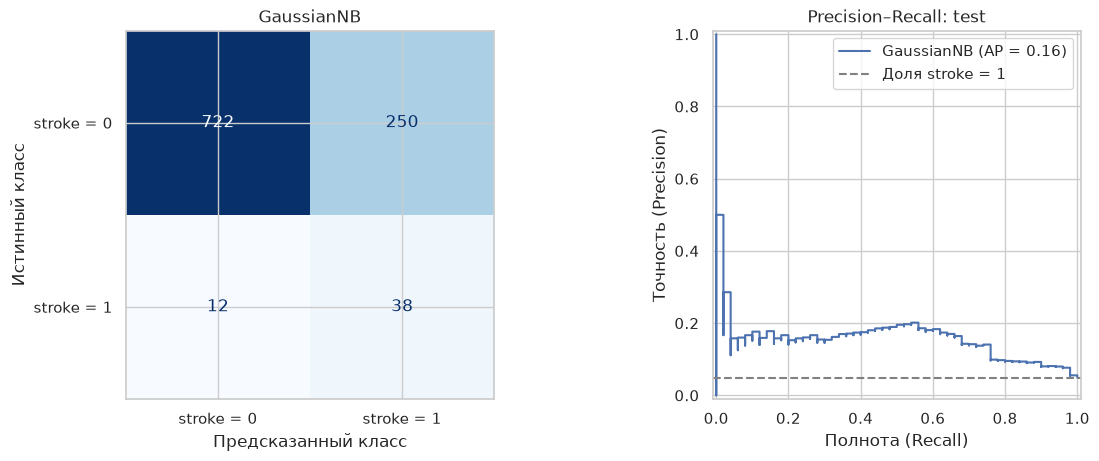

In [358]:
plot_classifier_results(y_test, nb_test_prediction, nb_test_probability, "GaussianNB")
plt.show()

In [359]:
print_model_conclusion("Наивный байесовский классификатор", nb_test_metrics)

Наивный байесовский классификатор: F1 = 0.225; обнаружено 76% положительных случаев; точность положительных прогнозов — 13.2%.


### 4.2. Логистическая регрессия
Используем ту же схему предобработки, что и для GaussianNB: заполнение пропусков, индикатор отсутствия BMI, масштабирование числовых признаков и one-hot-кодирование категорий. `clone` создаёт независимый необученный преобразователь. Pipeline обучает обработку заново внутри каждого фолда на исходном `X_train`.


In [360]:
lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(solver="lbfgs", max_iter=3000, random_state=RANDOM_STATE)),
])
lr_search = GridSearchCV(
    lr_pipeline,
    param_grid={
        "preprocessor__birth": [clone(categorical_transformer), "drop"],
        "classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "classifier__class_weight": [None, "balanced"],
    },
    scoring=SEARCH_SCORING, refit=True,
    cv=cv_splits, n_jobs=1, error_score="raise",
)
lr_search.fit(X_train, y_train)
lr_model = lr_search.best_estimator_
lr_search_results = pd.DataFrame(lr_search.cv_results_)[[
    "params", "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score")
print("Лучшие параметры:", lr_search.best_params_)
print(f"Average Precision при подборе: {lr_search.best_score_:.3f}")
lr_search_results.round(4)

Лучшие параметры: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'preprocessor__birth': 'drop'}
Average Precision при подборе: 0.220


,params,mean_test_score,std_test_score,rank_test_score
3,"{'classifier__C': 0.01, 'classifier__class_wei...",0.2204,0.0069,1
5,"{'classifier__C': 0.1, 'classifier__class_weig...",0.2180,0.0049,2
7,"{'classifier__C': 0.1, 'classifier__class_weig...",0.2169,0.0077,3
2,"{'classifier__C': 0.01, 'classifier__class_wei...",0.2160,0.0116,4
11,"{'classifier__C': 1.0, 'classifier__class_weig...",0.2142,0.0064,5
15,"{'classifier__C': 10.0, 'classifier__class_wei...",0.2139,0.0065,6
19,"{'classifier__C': 100.0, 'classifier__class_we...",0.2136,0.0065,7
9,"{'classifier__C': 1.0, 'classifier__class_weig...",0.2128,0.0061,8
6,"{'classifier__C': 0.1, 'classifier__class_weig...",0.2119,0.0188,9
17,"{'classifier__C': 100.0, 'classifier__class_we...",0.2110,0.0075,10


In [361]:
lr_test_probability = lr_model.predict_proba(X_test)[:, 1]
lr_test_prediction = lr_model.predict(X_test)
lr_test_metrics = pd.DataFrame({
    "LogisticRegression": evaluate_classifier(y_test, lr_test_prediction, lr_test_probability),
}).T
print(classification_report(y_test, lr_test_prediction, digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.988     0.754     0.855       972
           1      0.146     0.820     0.248        50

    accuracy                          0.757      1022
   macro avg      0.567     0.787     0.552      1022
weighted avg      0.947     0.757     0.826      1022



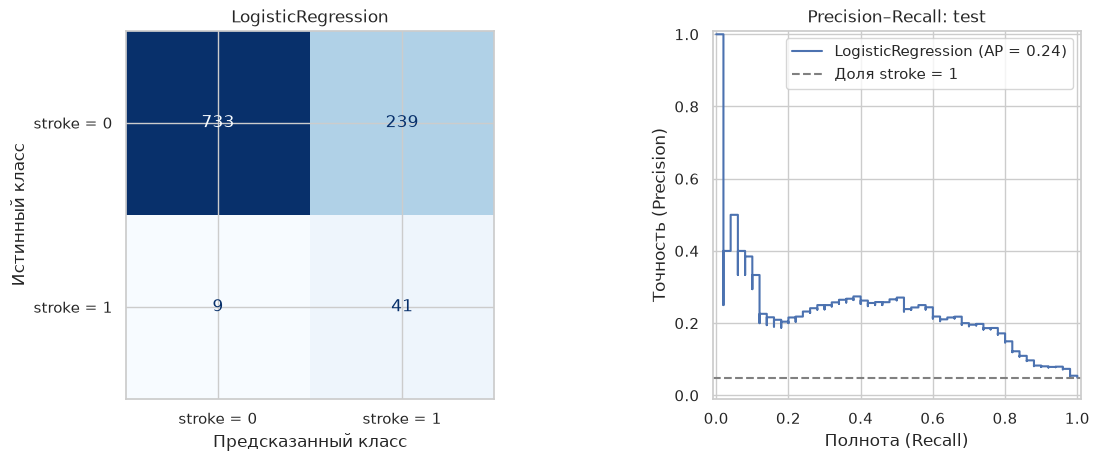

In [362]:
plot_classifier_results(y_test, lr_test_prediction, lr_test_probability, "LogisticRegression")
plt.show()

In [363]:
print_model_conclusion("Логистическая регрессия", lr_test_metrics)

Логистическая регрессия: F1 = 0.248; обнаружено 82% положительных случаев; точность положительных прогнозов — 14.6%.


### 4.3. Дерево решений
`GridSearchCV` перебирает все 640 комбинаций параметров по Average Precision на общих фолдах `cv_splits`. Поиск включает вариант с городом/месяцем рождения и без них (`preprocessor__birth="drop"`). Подбираются глубина, размер листа, ccp_alpha и веса классов.


In [364]:
dt_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

dt_param_distributions = {
    "preprocessor__birth": [clone(categorical_transformer), "drop"],
    "classifier__max_depth": [3, 5, 8, 12, None],
    "classifier__min_samples_leaf": [5, 10, 20, 50],
    "classifier__ccp_alpha": [0.0, 0.0001, 0.001, 0.005],
    "classifier__class_weight": [None, "balanced", {0: 1, 1: 5}, {0: 1, 1: 10}],
}
dt_search = RandomizedSearchCV(
    dt_pipeline, param_distributions=dt_param_distributions,
    n_iter=12, scoring=SEARCH_SCORING, cv=cv_splits,
    random_state=RANDOM_STATE, refit=True, n_jobs=1, error_score="raise",
)

In [365]:
dt_search.fit(X_train, y_train)
dt_model = dt_search.best_estimator_
dt_search_results = pd.DataFrame(dt_search.cv_results_)[[
    "params", "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score")
print("Лучшие параметры:", dt_search.best_params_)
print(f"Average Precision при подборе: {dt_search.best_score_:.3f}")
dt_search_results.round(4)

Лучшие параметры: {'preprocessor__birth': Pipeline(steps=[('imputer',
                 SimpleImputer(fill_value='Unknown', strategy='constant')),
                ('encoder',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), 'classifier__min_samples_leaf': 50, 'classifier__max_depth': 5, 'classifier__class_weight': None, 'classifier__ccp_alpha': 0.0001}
Average Precision при подборе: 0.176


,params,mean_test_score,std_test_score,rank_test_score
4,{'preprocessor__birth': (SimpleImputer(fill_va...,0.1762,0.0162,1
8,"{'preprocessor__birth': 'drop', 'classifier__m...",0.1721,0.0136,2
6,{'preprocessor__birth': (SimpleImputer(fill_va...,0.1605,0.0257,3
0,{'preprocessor__birth': (SimpleImputer(fill_va...,0.1603,0.0176,4
3,"{'preprocessor__birth': 'drop', 'classifier__m...",0.1603,0.0176,4
2,"{'preprocessor__birth': 'drop', 'classifier__m...",0.1557,0.0314,6
5,"{'preprocessor__birth': 'drop', 'classifier__m...",0.1535,0.0063,7
11,"{'preprocessor__birth': 'drop', 'classifier__m...",0.1363,0.0107,8
10,"{'preprocessor__birth': 'drop', 'classifier__m...",0.1292,0.0372,9
7,"{'preprocessor__birth': 'drop', 'classifier__m...",0.1281,0.0145,10


In [366]:
# Проверочные вероятности для отдельного подбора порога на train
dt_oof_probability = cross_val_predict(
    clone(dt_model), X_train, y_train,
    cv=cv_splits, method="predict_proba", n_jobs=1,
)[:, 1]
dt_threshold, dt_threshold_f1 = select_f1_threshold(y_train, dt_oof_probability)
print(f"Порог по train: {dt_threshold:.4f}; F1 при подборе: {dt_threshold_f1:.3f}")

Порог по train: 0.1176; F1 при подборе: 0.268


In [367]:
dt_test_probability = dt_model.predict_proba(X_test)[:, 1]
dt_test_prediction = (dt_test_probability >= dt_threshold).astype(int)
dt_test_metrics = pd.DataFrame({"DecisionTree": evaluate_classifier(y_test, dt_test_prediction, dt_test_probability)}).T
print(classification_report(y_test, dt_test_prediction, digits=3, zero_division=0))
dt_test_metrics.round(4)

              precision    recall  f1-score   support

           0      0.973     0.891     0.930       972
           1      0.197     0.520     0.286        50

    accuracy                          0.873      1022
   macro avg      0.585     0.705     0.608      1022
weighted avg      0.935     0.873     0.899      1022



,Accuracy,Precision (stroke=1),Recall (stroke=1),F1 (stroke=1),Average Precision,ROC-AUC
DecisionTree,0.8728,0.197,0.52,0.2857,0.1761,0.794


In [368]:
print_model_conclusion("Дерево решений", dt_test_metrics)

Дерево решений: F1 = 0.286; обнаружено 52% положительных случаев; точность положительных прогнозов — 19.7%.


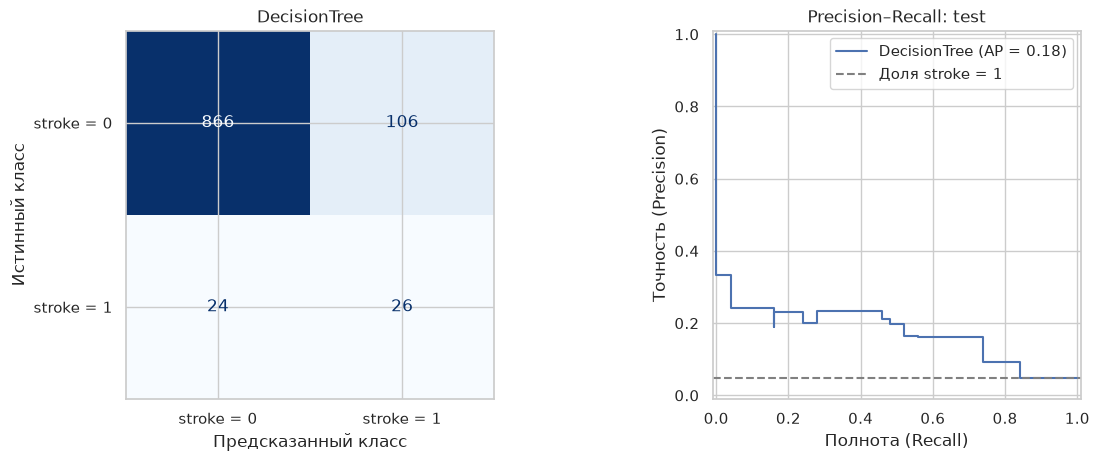

In [369]:
plot_classifier_results(y_test, dt_test_prediction, dt_test_probability, "DecisionTree")
plt.show()

### 4.4. Случайный лес
`GridSearchCV` перебирает все 288 комбинаций параметров по Average Precision на общих фолдах `cv_splits`. Поиск включает вариант с городом/месяцем рождения и без них (`preprocessor__birth="drop"`). Лес содержит 500 деревьев; подбираются глубина, размер листа, max_features и веса классов.


In [370]:
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(n_estimators=500, n_jobs=2, random_state=RANDOM_STATE)),
])

rf_param_distributions = {
    "preprocessor__birth": [clone(categorical_transformer), "drop"],
    "classifier__max_depth": [5, 10, 20, None],
    "classifier__min_samples_leaf": [1, 5, 10, 20],
    "classifier__max_features": ["sqrt", 0.5, 1.0],
    "classifier__class_weight": [None, "balanced_subsample", {0: 1, 1: 5}],
}
rf_search = RandomizedSearchCV(
    rf_pipeline, param_distributions=rf_param_distributions,
    n_iter=12, scoring=SEARCH_SCORING, cv=cv_splits,
    random_state=RANDOM_STATE, refit=True, n_jobs=1, error_score="raise",
)

In [371]:
rf_search.fit(X_train, y_train)
rf_model = rf_search.best_estimator_
rf_search_results = pd.DataFrame(rf_search.cv_results_)[[
    "params", "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score")
print("Лучшие параметры:", rf_search.best_params_)
print(f"Average Precision при подборе: {rf_search.best_score_:.3f}")
rf_search_results.round(4)

Лучшие параметры: {'preprocessor__birth': 'drop', 'classifier__min_samples_leaf': 1, 'classifier__max_features': 0.5, 'classifier__max_depth': 5, 'classifier__class_weight': None}
Average Precision при подборе: 0.242


,params,mean_test_score,std_test_score,rank_test_score
5,"{'preprocessor__birth': 'drop', 'classifier__m...",0.2417,0.0323,1
3,{'preprocessor__birth': (SimpleImputer(fill_va...,0.2112,0.0245,2
6,{'preprocessor__birth': (SimpleImputer(fill_va...,0.2085,0.0054,3
9,"{'preprocessor__birth': 'drop', 'classifier__m...",0.2085,0.0068,4
0,"{'preprocessor__birth': 'drop', 'classifier__m...",0.2062,0.0151,5
4,"{'preprocessor__birth': 'drop', 'classifier__m...",0.2048,0.0153,6
1,"{'preprocessor__birth': 'drop', 'classifier__m...",0.2048,0.0153,6
11,"{'preprocessor__birth': 'drop', 'classifier__m...",0.2010,0.0168,8
8,"{'preprocessor__birth': 'drop', 'classifier__m...",0.2001,0.0095,9
7,{'preprocessor__birth': (SimpleImputer(fill_va...,0.1891,0.0065,10


In [372]:
# Проверочные вероятности для отдельного подбора порога на train
rf_oof_probability = cross_val_predict(
    clone(rf_model), X_train, y_train,
    cv=cv_splits, method="predict_proba", n_jobs=1,
)[:, 1]
rf_threshold, rf_threshold_f1 = select_f1_threshold(y_train, rf_oof_probability)
print(f"Порог по train: {rf_threshold:.4f}; F1 при подборе: {rf_threshold_f1:.3f}")

Порог по train: 0.1238; F1 при подборе: 0.304


In [373]:
rf_test_probability = rf_model.predict_proba(X_test)[:, 1]
rf_test_prediction = (rf_test_probability >= rf_threshold).astype(int)
rf_test_metrics = pd.DataFrame({"RandomForest": evaluate_classifier(y_test, rf_test_prediction, rf_test_probability)}).T
print(classification_report(y_test, rf_test_prediction, digits=3, zero_division=0))
rf_test_metrics.round(4)

              precision    recall  f1-score   support

           0      0.976     0.906     0.940       972
           1      0.235     0.560     0.331        50

    accuracy                          0.889      1022
   macro avg      0.605     0.733     0.636      1022
weighted avg      0.939     0.889     0.910      1022



,Accuracy,Precision (stroke=1),Recall (stroke=1),F1 (stroke=1),Average Precision,ROC-AUC
RandomForest,0.8894,0.2353,0.56,0.3314,0.207,0.8366


In [374]:
print_model_conclusion("Случайный лес", rf_test_metrics)

Случайный лес: F1 = 0.331; обнаружено 56% положительных случаев; точность положительных прогнозов — 23.5%.


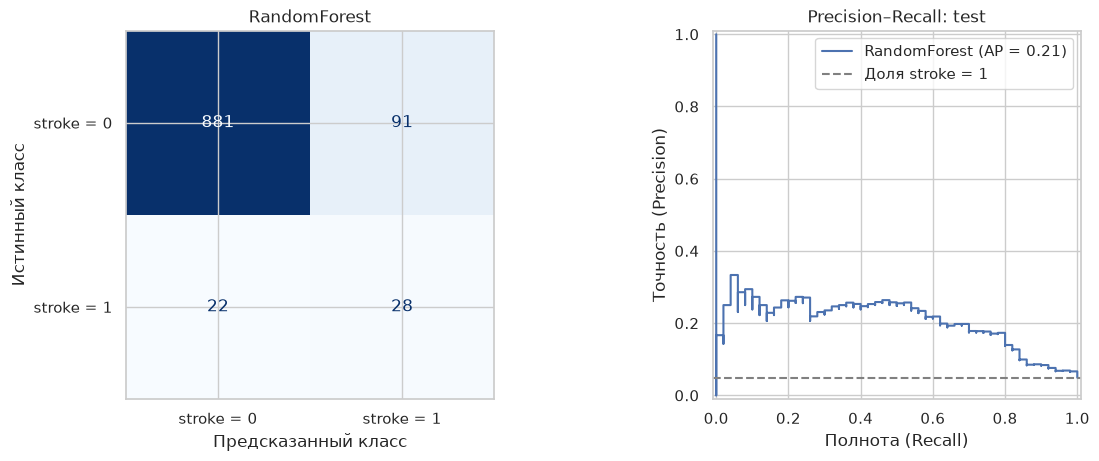

In [375]:
plot_classifier_results(y_test, rf_test_prediction, rf_test_probability, "RandomForest")
plt.show()

## 5. Построение и обучение небольшой нейронной сети
`MLPClassifier` обучается внутри Pipeline с заполнением пропусков, масштабированием и one-hot-кодированием. `GridSearchCV` перебирает все 32 комбинации параметров: архитектуру, L2-регуляризацию, скорость обучения, использование группы birth и отсутствие балансировки / RandomOverSampler. Oversampling применяется только к обучающей части каждого фолда. Оптимизатор — Adam; встроенная остановка по accuracy отключена.

На трёх фолдах это 96 обучений при подборе, затем переобучение выбранной модели на всём train. Параметры выбираются по AP, затем порог отдельно подбирается по F1 на train. Test не участвует в подборе.


In [376]:
nn_pipeline = ResamplingPipeline([
    ("preprocessor", clone(preprocessor)),
    ("sampler", "passthrough"),
    ("classifier", MLPClassifier(hidden_layer_sizes=(32, 16),
        activation="relu", solver="adam", batch_size=128,
        max_iter=2000, early_stopping=False, n_iter_no_change=20,
        tol=1e-4, random_state=RANDOM_STATE)),
])

nn_param_grid = {
    "preprocessor__birth": [clone(categorical_transformer), "drop"],
    "classifier__hidden_layer_sizes": [(16,), (32, 16)],
    "classifier__alpha": [0.01, 0.1],
    "classifier__learning_rate_init": [0.001, 0.0005],
    "sampler": ["passthrough", RandomOverSampler(random_state=RANDOM_STATE)],
}

nn_search = GridSearchCV(
    nn_pipeline, param_grid=nn_param_grid,
    scoring=SEARCH_SCORING, cv=cv_splits,
    refit=True, n_jobs=1, error_score="raise",
)

In [377]:
nn_search.fit(X_train, y_train)
nn_model = nn_search.best_estimator_

nn_search_results = pd.DataFrame(nn_search.cv_results_)[[
    "params", "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score")
print("Лучшие параметры:", nn_search.best_params_)
print(f"Average Precision при подборе: {nn_search.best_score_:.3f}")
print("Эпох в финальном обучении:", nn_model.named_steps["classifier"].n_iter_)
nn_search_results.round(4)

Лучшие параметры: {'classifier__alpha': 0.1, 'classifier__hidden_layer_sizes': (16,), 'classifier__learning_rate_init': 0.0005, 'preprocessor__birth': 'drop', 'sampler': 'passthrough'}
Average Precision при подборе: 0.242
Эпох в финальном обучении: 180


,params,mean_test_score,std_test_score,rank_test_score
22,"{'classifier__alpha': 0.1, 'classifier__hidden...",0.2421,0.0268,1
6,"{'classifier__alpha': 0.01, 'classifier__hidde...",0.2319,0.0269,2
18,"{'classifier__alpha': 0.1, 'classifier__hidden...",0.2283,0.0194,3
19,"{'classifier__alpha': 0.1, 'classifier__hidden...",0.2037,0.0396,4
2,"{'classifier__alpha': 0.01, 'classifier__hidde...",0.2013,0.0161,5
23,"{'classifier__alpha': 0.1, 'classifier__hidden...",0.1988,0.0201,6
3,"{'classifier__alpha': 0.01, 'classifier__hidde...",0.1676,0.0235,7
21,"{'classifier__alpha': 0.1, 'classifier__hidden...",0.1669,0.0161,8
5,"{'classifier__alpha': 0.01, 'classifier__hidde...",0.1668,0.0190,9
17,"{'classifier__alpha': 0.1, 'classifier__hidden...",0.1644,0.0242,10


In [378]:
# Проверочные вероятности для отдельного подбора порога на train
nn_oof_probability = cross_val_predict(
    clone(nn_model), X_train, y_train,
    cv=cv_splits, method="predict_proba", n_jobs=1,
)[:, 1]
nn_threshold, nn_threshold_f1 = select_f1_threshold(y_train, nn_oof_probability)
print(f"Порог по train: {nn_threshold:.4f}; F1 при подборе порога: {nn_threshold_f1:.3f}")

Порог по train: 0.1352; F1 при подборе порога: 0.293


In [379]:
nn_test_probability = nn_model.predict_proba(X_test)[:, 1]
nn_test_prediction = (nn_test_probability >= nn_threshold).astype(int)
nn_test_metrics = pd.DataFrame({
    "MLP": evaluate_classifier(y_test, nn_test_prediction, nn_test_probability),
}).T
print(classification_report(y_test, nn_test_prediction, digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.971     0.905     0.937       972
           1      0.207     0.480     0.289        50

    accuracy                          0.885      1022
   macro avg      0.589     0.693     0.613      1022
weighted avg      0.934     0.885     0.905      1022



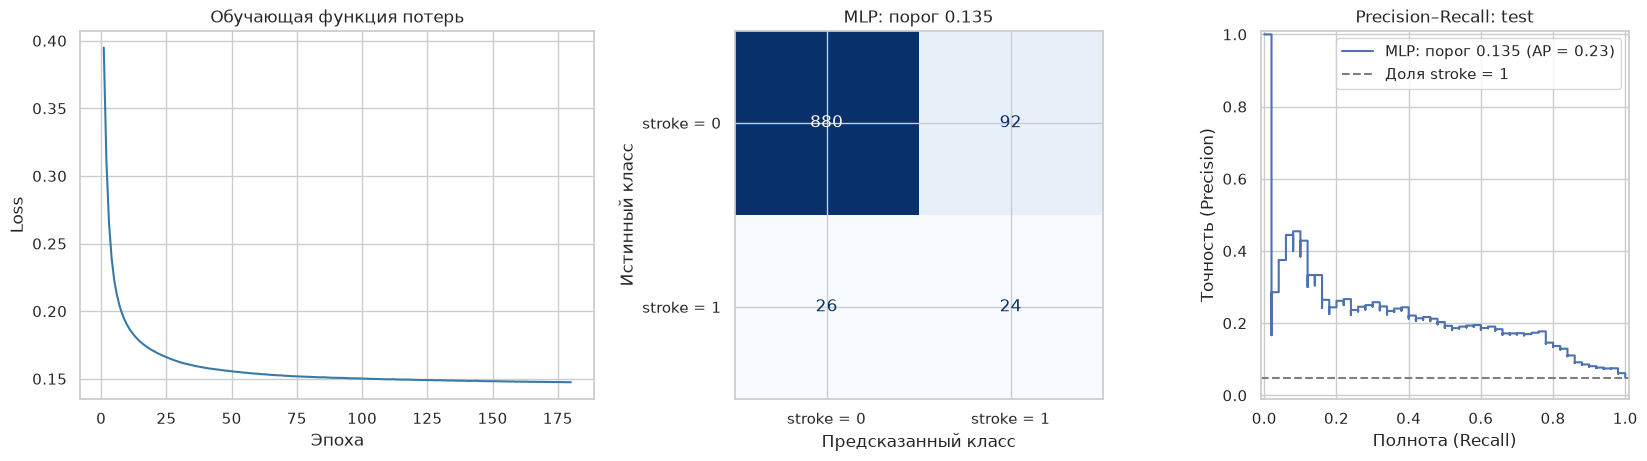

In [380]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), layout="constrained")
loss_curve = nn_model.named_steps["classifier"].loss_curve_
axes[0].plot(range(1, len(loss_curve) + 1), loss_curve, color="#3979A8")
axes[0].set(title="Обучающая функция потерь", xlabel="Эпоха", ylabel="Loss")
plot_classifier_results(y_test, nn_test_prediction, nn_test_probability, f"MLP: порог {nn_threshold:.3f}", axes=axes[1:])
plt.show()

In [381]:
print_model_conclusion("Нейросеть", nn_test_metrics)

Нейросеть: F1 = 0.289; обнаружено 48% положительных случаев; точность положительных прогнозов — 20.7%.


### 5.1. Итоговое сравнение
Пять обученных моделей и общий базовый ориентир оцениваются на одном test. Для дерева, леса и нейросети используются пороги, выбранные на train. Метрики внутренних проверок используются для настройки, а не как независимая оценка.


In [382]:
final_comparison = pd.concat([dummy_metrics, nb_test_metrics, lr_test_metrics, dt_test_metrics, rf_test_metrics, nn_test_metrics])
final_comparison.round(4)

,Accuracy,Precision (stroke=1),Recall (stroke=1),F1 (stroke=1),Average Precision,ROC-AUC
DummyClassifier,0.9511,0.0000,0.00,0.0000,0.0489,0.5000
GaussianNB,0.7436,0.1319,0.76,0.2249,0.1580,0.8035
LogisticRegression,0.7573,0.1464,0.82,0.2485,0.2364,0.8409
DecisionTree,0.8728,0.1970,0.52,0.2857,0.1761,0.7940
RandomForest,0.8894,0.2353,0.56,0.3314,0.2070,0.8366
MLP,0.8845,0.2069,0.48,0.2892,0.2267,0.8321


In [383]:
comparison = final_comparison.drop(index="DummyClassifier", errors="ignore")
for metric, label in [("F1 (stroke=1)", "F1"), ("Recall (stroke=1)", "Recall")]:
    best_value = comparison[metric].max()
    names = ", ".join(comparison.index[comparison[metric] == best_value])
    print(f"На test наибольший {label}: {names} ({best_value:.3f}).")

На test наибольший F1: RandomForest (0.331).
На test наибольший Recall: LogisticRegression (0.820).
